In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# Daten Laden

In [2]:
#label laden
df = pd.read_csv("labels.csv", sep=";")
df["id"] = df["Filename"].str.split(".").str[0]
print(df["Species"].value_counts())

Species
Langohrfledermaus      197
Fransenfledermaus      163
Bartfledermaus         113
Bechsteinfledermaus    104
Wasserfledermaus         5
Mausohr                  4
Name: count, dtype: int64


# Erste Datenübersicht

In [3]:
df.shape

(586, 4)

In [4]:
df.head()

,Filename,ID,Species,id
0,1504695082.jpg,1504695082,Bechsteinfledermaus,1504695082
1,1504714350.jpg,1504714350,Bechsteinfledermaus,1504714350
2,1504715079.jpg,1504715079,Bechsteinfledermaus,1504715079
3,1504716272.jpg,1504716272,Bechsteinfledermaus,1504716272
4,1504716318.jpg,1504716318,Bechsteinfledermaus,1504716318


In [5]:
from pathlib import Path
# Dateipfad ändern, da Filename in df auf .jpg ändert, die Images aber als .png abgespeichert sind
image_dir = Path("images")

filename = Path(df.iloc[0]["Filename"]).with_suffix(".png") # Endung .jpg in df wird durch .png ersetzt
image_path = image_dir / filename

print("Bildpfad:", image_path)
print("Datei vorhanden:", image_path.exists())

Bildpfad: images/1504695082.png
Datei vorhanden: True


Bildgröße: (432, 288)
Bildmodus: RGBA


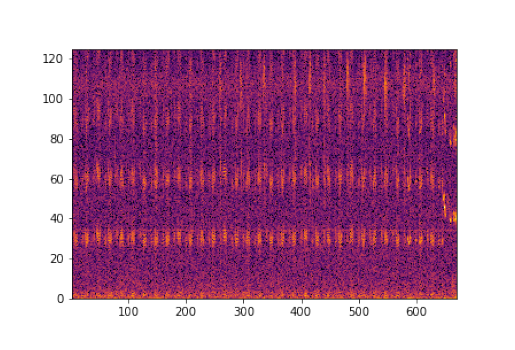

In [6]:
# Spektrogramm laden
img = Image.open(image_path)

print("Bildgröße:", img.size)
print("Bildmodus:", img.mode)

plt.imshow(img)
plt.axis("off")
plt.show()

In [7]:
# Prüfen, ob alle Spektrogramme dieselben Dimensionen haben und ob alle Dateien vorhanden sind
from collections import Counter
from PIL import Image

sizes = []
missing = []

for filename in df["Filename"]:
    image_path = image_dir / Path(filename).with_suffix(".png")

    if image_path.exists():
        with Image.open(image_path) as img:
            sizes.append(img.size)
    else:
        missing.append(filename)

print("Bildgrößen:", Counter(sizes))
print("Fehlende Bilder:", len(missing))

Bildgrößen: Counter({(432, 288): 585})
Fehlende Bilder: 1


In [8]:
print(missing)

['1508192440.jpg']


In [9]:
# Prüfen, zu welcher Art, der fehlende Eintrag gehört
df.loc[df["Filename"] == "1508192440.jpg"]

,Filename,ID,Species,id
367,1508192440.jpg,1508192440,Langohrfledermaus,1508192440


In [10]:
# Prüfen, ob fehlende Datei unter anderer Endung vorhanden ist
list(image_dir.glob("1508192440*"))

[]

Ergebnis der ersten Datenprüfung:
Bei der initialen Dateninspektion wurde festgestellt, dass von 583 referenzierten Spektrogrammen 582 Bilddateien vorhanden sind. Alle vorhandenen Bilder weisen einheitliche Dimensionen von 432 × 288 Pixeln auf. Ein Spektrogramm der Klasse Langohrfledermaus fehlt.

# Data Cleaning

In [11]:
# 1. Seltene Fledermausarten ausschließen
excluded = ["Wasserfledermaus", "Mausohr"]

df_model = df[~df["Species"].isin(excluded)].copy()

# 2. Eintrag mit fehlendem Spektrogramm entfernen
df_model = df_model[
    df_model["Filename"] != "1508192440.jpg"
].copy()

# 3. Ergebnis kontrollieren
print(df_model["Species"].value_counts())
print("Gesamt:", len(df_model))

Species
Langohrfledermaus      196
Fransenfledermaus      163
Bartfledermaus         113
Bechsteinfledermaus    104
Name: count, dtype: int64
Gesamt: 576


In [13]:
""" Prüfen, ob mehrere Spektrogramme aus derselben Aufnahme stammen: Das ist wichtig, bevor wir die Daten in Trainings- und Testdaten aufteilen. 
Andernfalls könnten sehr ähnliche Rufe derselben Aufnahme in beiden Datensätzen landen und die Modellbewertung verfälschen (Data Leakage)."""


print("Anzahl eindeutiger IDs:")
print(df_model["ID"].nunique())
print(df_model["id"].nunique())

print("\nSind beide Spalten identisch?")
print((df_model["ID"].astype(str) == df_model["id"].astype(str)).all())

print("\nGibt es doppelte IDs?")
print(df_model["ID"].duplicated().sum())

Anzahl eindeutiger IDs:
573
573

Sind beide Spalten identisch?
True

Gibt es doppelte IDs?
3


In [15]:
# Doppelte IDs anzeigen
duplicates = df_model[
    df_model["ID"].duplicated(keep=False)
].sort_values("ID")

display(duplicates)

,Filename,ID,Species,id
353,1508120329.jpg,1508120329,Bartfledermaus,1508120329
354,1508120329.jpg,1508120329,Bartfledermaus,1508120329
362,1508187294.jpg,1508187294,Langohrfledermaus,1508187294
363,1508187294.jpg,1508187294,Langohrfledermaus,1508187294
542,1509510231.jpg,1509510231,Fransenfledermaus,1509510231
543,1509510231.jpg,1509510231,Fransenfledermaus,1509510231


In [16]:
# Duplikate können entfernt werden, da die Zeilen identisch sind.

df_model = df_model.drop_duplicates().copy()

print("Anzahl Beobachtungen:", len(df_model))
print("Doppelte Zeilen:", df_model.duplicated().sum())

Anzahl Beobachtungen: 573
Doppelte Zeilen: 0
